# Solutions to notebook 1: Differentiation matrices: from finite differences to spectral accuracy

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/solutions/01_differentiation_matrices.ipynb)

Worked solutions to the exercises at the end of [notebook 1](../notebooks/01_differentiation_matrices.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial
from scipy.optimize import brentq

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# functions from notebook 1
r_crank, l_rod = 1.0, 3.0

def position(theta):
    return r_crank * np.cos(theta) + np.sqrt(l_rod**2 - r_crank**2 * np.sin(theta) ** 2)

def velocity(theta):                        # ds/dθ, exact
    root = np.sqrt(l_rod**2 - r_crank**2 * np.sin(theta) ** 2)
    return -r_crank * np.sin(theta) - r_crank**2 * np.sin(theta) * np.cos(theta) / root

def acceleration(theta):                    # d²s/dθ², exact
    root = np.sqrt(l_rod**2 - r_crank**2 * np.sin(theta) ** 2)
    return (-r_crank * np.cos(theta) - r_crank**2 * np.cos(2 * theta) / root
            - r_crank**4 * np.sin(theta) ** 2 * np.cos(theta) ** 2 / root**3)

def fd2_matrix(N):
    """Second-order centred difference matrix on a periodic grid of N points."""
    h = 2 * np.pi / N
    D = np.zeros((N, N))
    for j in range(N):
        D[j, (j + 1) % N] = 1 / (2 * h)
        D[j, (j - 1) % N] = -1 / (2 * h)
    return D

def fd_weights(m):
    """Weights α_1..α_m of the centred difference formula of order 2m."""
    return np.array([(-1) ** (k + 1) * factorial(m) ** 2 / (k * factorial(m - k) * factorial(m + k))
                     for k in range(1, m + 1)])

def fd_matrix(N, m):
    """Centred difference matrix of order 2m on a periodic grid of N points."""
    h = 2 * np.pi / N
    D = np.zeros((N, N))
    for k, alpha in enumerate(fd_weights(m), start=1):
        for j in range(N):
            D[j, (j + k) % N] += alpha / h
            D[j, (j - k) % N] -= alpha / h
    return D

def fourier_diff_matrix(N):
    """First-derivative matrix for the periodic grid of N points (N even)."""
    if N % 2:
        raise ValueError("N must be even")
    h = 2 * np.pi / N
    k = np.arange(N)[:, None] - np.arange(N)[None, :]          # i - j for every entry
    D = np.zeros((N, N))
    off = k != 0
    D[off] = 0.5 * (-1.0) ** k[off] / np.tan(k[off] * h / 2)
    return D

def max_error(D, N):
    theta = 2 * np.pi * np.arange(N) / N
    return np.abs(D @ position(theta) - velocity(theta)).max()

## Exercise 1

Add the sixth-order formula ($m = 3$) to the convergence plot of 1.5 and confirm its slope.
At what $N$ does it first beat the fourth-order formula by a factor of 100?

The plot of 1.5 is repeated with one more entry in the dictionary of methods. A formula of
order 6 should appear as a straight line of slope $-6$ on the logarithmic axes. The fourth-order
error falls like $N^{-4}$ and the sixth-order error like $N^{-6}$, so their ratio grows like
$N^2$ and must pass 100 somewhere.

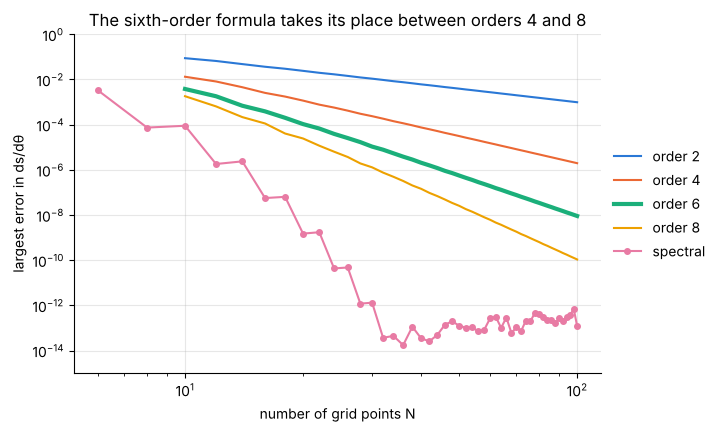

In [3]:
N_values = np.arange(10, 101, 2)
methods = {"order 2": lambda n: fd_matrix(n, 1), "order 4": lambda n: fd_matrix(n, 2),
           "order 6": lambda n: fd_matrix(n, 3), "order 8": lambda n: fd_matrix(n, 4)}
errors = {name: np.array([max_error(build(n), n) for n in N_values]) for name, build in methods.items()}
N_spectral = np.arange(6, 101, 2)
errors_spectral = np.array([max_error(fourier_diff_matrix(n), n) for n in N_spectral])

fig, ax = plt.subplots(figsize=(6.8, 4.4))
for name, err in errors.items():
    ax.loglog(N_values, err, lw=3 if name == "order 6" else 1.5, label=name)
ax.loglog(N_spectral, errors_spectral, "o-", ms=4, lw=1.5, label="spectral")
ax.set(xlabel="number of grid points N", ylabel="largest error in ds/dθ", ylim=(1e-15, 1),
       title="The sixth-order formula takes its place between orders 4 and 8")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [4]:
late = N_values >= 50                                          # the asymptotic part of the curve
slope = np.polyfit(np.log(N_values[late]), np.log(errors["order 6"][late]), 1)[0]
ratio = errors["order 4"] / errors["order 6"]
N_first = int(N_values[np.argmax(ratio >= 100)])
print(f"fitted slope of the sixth-order error for N ≥ 50: {slope:.2f}")
print(f"error ratio order 4 / order 6:  N = 66: {ratio[N_values == 66][0]:.1f}   N = 68: {ratio[N_values == 68][0]:.1f}")
print(f"first even N with a ratio of at least 100: {N_first}")

fitted slope of the sixth-order error for N ≥ 50: -5.95
error ratio order 4 / order 6:  N = 66: 95.8   N = 68: 101.9
first even N with a ratio of at least 100: 68


For an independent check, use the leading error terms of the two formulas, which a Taylor
expansion gives as $\tfrac{1}{30}h^4 s^{(5)}$ and $\tfrac{1}{140}h^6 s^{(7)}$. The high derivatives are
computed with the spectral matrix on 64 points, where it is accurate to many digits. Setting the
ratio of the two terms to 100 and solving for $N = 2\pi/h$ predicts the crossing.

In [5]:
# verify: the slope against the order of the formula, the crossing against the leading error terms
D = fourier_diff_matrix(64)
s = position(2 * np.pi * np.arange(64) / 64)
s5, s7 = np.abs(np.linalg.matrix_power(D, 5) @ s).max(), np.abs(np.linalg.matrix_power(D, 7) @ s).max()
N_predicted = 2 * np.pi * np.sqrt(100 * 30 * s7 / (140 * s5))
print(f"max |s⁽⁵⁾| = {s5:.3f}, max |s⁽⁷⁾| = {s7:.2f}, predicted crossing at N = {N_predicted:.1f}")
assert abs(slope + 6) < 0.15
assert abs(N_first - N_predicted) < 2
assert abs(errors["order 6"][-1] / ((2 * np.pi / 100) ** 6 / 140 * s7) - 1) < 0.05     # error at N = 100 against its leading term

max |s⁽⁵⁾| = 3.791, max |s⁽⁷⁾| = 20.84, predicted crossing at N = 68.2


**Answer.** The sixth-order line has a fitted slope of $-5.95$ for $N \ge 50$, approaching $-6$
as $N$ grows. It first beats the fourth-order formula by a factor of 100 at
$N = 68$ (the ratio is 95.8 at $N = 66$ and 101.9 at $N = 68$), and the leading error terms
predict the crossing at $N = 68.2$. Two extra orders buy two digits only on a grid that is
already fairly fine: the gain from raising the order grows with $N$.

## Exercise 2

Lengthen the connecting rod to $l = 6r$ and repeat the spectral convergence test. How does
the decay rate change, and how many points now give 12 digits?

Only the rod length changes. Notebook 1 predicts the decay rate $e^{-\mathrm{arccosh}(l/r)\,N/2}$, so
a longer rod should converge faster: $\mathrm{arccosh}(6)/2 = 1.24$ against
$\mathrm{arccosh}(3)/2 = 0.88$. The rate is fitted on the part of the curve that lies above the
rounding level, which is now reached earlier.

l = 3 r: fitted rate 0.879, predicted arccosh(l/r)/2 = 0.881, first N with an error below 1e-12: 32
l = 6 r: fitted rate 1.257, predicted arccosh(l/r)/2 = 1.239, first N with an error below 1e-12: 20


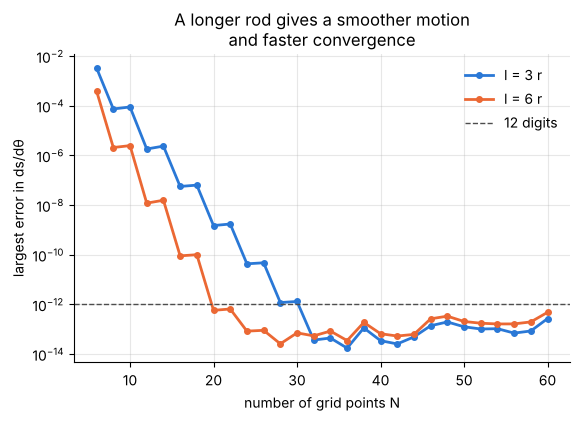

In [6]:
def spectral_error(N, l):
    """Largest error of the spectral velocity for a rod of length l (crank radius 1)."""
    theta = 2 * np.pi * np.arange(N) / N
    root = np.sqrt(l**2 - np.sin(theta) ** 2)
    return np.abs(fourier_diff_matrix(N) @ (np.cos(theta) + root) - (-np.sin(theta) - np.sin(theta) * np.cos(theta) / root)).max()

N_values = np.arange(6, 61, 2)
results = {}
for l, window in ((3.0, (8, 34)), (6.0, (8, 20))):             # window: before rounding errors take over
    err = np.array([spectral_error(n, l) for n in N_values])
    fit = (N_values >= window[0]) & (N_values <= window[1])
    rate = -np.polyfit(N_values[fit], np.log(err[fit]), 1)[0]
    N_twelve = int(N_values[np.argmax(err < 1e-12)])
    results[l] = (err, rate, N_twelve)
    print(f"l = {l:.0f} r: fitted rate {rate:.3f}, predicted arccosh(l/r)/2 = {np.arccosh(l) / 2:.3f}, "
          f"first N with an error below 1e-12: {N_twelve}")

fig, ax = plt.subplots()
for l, (err, rate, N_twelve) in results.items():
    ax.semilogy(N_values, err, "o-", ms=4, label=f"l = {l:.0f} r")
ax.axhline(1e-12, color="0.3", lw=1, ls="--", label="12 digits")
ax.set(xlabel="number of grid points N", ylabel="largest error in ds/dθ",
       title="A longer rod gives a smoother motion\nand faster convergence")
ax.legend(frameon=False, loc="upper right");

In [7]:
# verify: the fitted rates against the prediction arccosh(l/r)/2, and the long rod against the short one
assert np.isclose(spectral_error(40, 3.0), max_error(fourier_diff_matrix(40), 40))        # same calculation as the lesson for l = 3
for l, (err, rate, N_twelve) in results.items():
    assert abs(rate / (np.arccosh(l) / 2) - 1) < 0.05
assert results[6.0][2] == 20 and results[3.0][2] == 32
assert abs(results[6.0][2] / results[3.0][2] - np.arccosh(3) / np.arccosh(6)) < 0.1   # points needed scale inversely with the rate

**Answer.** The decay rate rises from $e^{-0.88N}$ to $e^{-1.26N}$ (fitted; predicted
$\mathrm{arccosh}(6)/2 = 1.24$), and 12 digits are reached with $N = 20$ points instead of 32.
The ratio of the two point counts, 0.63, is close to the inverse ratio of the rates, 0.71. The
smoother the motion, the fewer samples a spectral method needs.

## Exercise 3

The spectral matrix was derived for a smooth periodic function. Apply it with $N = 64$ to
the ramp $u(x) = x$ on $[0, 2\pi)$, whose periodic extension jumps. Plot the result
against the exact derivative 1 and describe what you see.

The matrix differentiates the periodic interpolant of the data, and the periodic extension of
$u = x$ falls by $2\pi$ at $x = 0$. Expect trouble there. A prediction can be made by hand with
the infinite-order weights $\alpha_k = (-1)^{k+1}/k$ of section 1.4. At the point $x_0 = 0$ the
neighbours are $u_k = kh$ and $u_{-k} = 2\pi - kh$, so

$$\frac1h\sum_k \alpha_k\,(u_k - u_{-k}) = \frac1h\sum_k\alpha_k\,2kh \;-\; \frac{2\pi}{h}\sum_k \alpha_k
= 1 - N\ln 2 ,$$

because the first sum differentiates the straight line exactly and $\sum_k (-1)^{k+1}/k = \ln 2$.
The error at the jump should grow in proportion to $N$.

N = 64:  value at x = 0: -43.35   1 − N ln 2 = -43.36   mean of all values: -3.5e-15
N = 256: value at x = 0: -176.44   1 − N ln 2 = -176.45
N =  64: error at x = π/2: 1.49   at x = π: 0.0385
N = 256: error at x = π/2: 1.55   at x = π: 0.0096


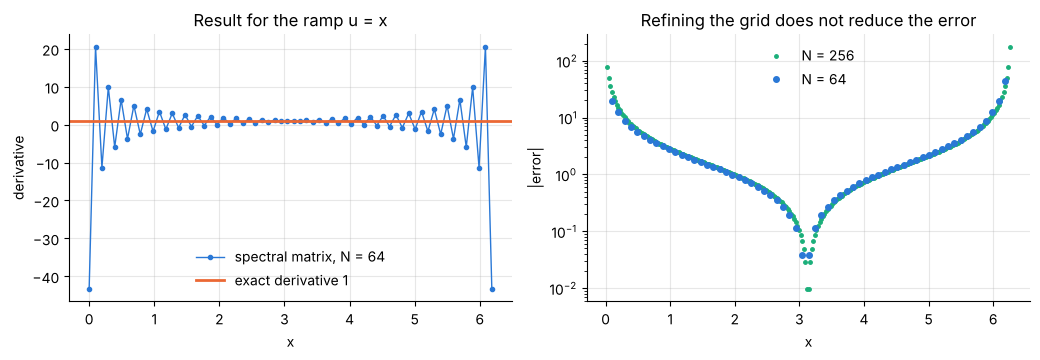

In [8]:
def ramp_derivative(N):
    x = 2 * np.pi * np.arange(N) / N
    return x, fourier_diff_matrix(N) @ x

x, w = ramp_derivative(64)
x_fine, w_fine = ramp_derivative(256)
print(f"N = 64:  value at x = 0: {w[0]:.2f}   1 − N ln 2 = {1 - 64 * np.log(2):.2f}   mean of all values: {w.mean():.1e}")
print(f"N = 256: value at x = 0: {w_fine[0]:.2f}   1 − N ln 2 = {1 - 256 * np.log(2):.2f}")
for N, values in ((64, w), (256, w_fine)):
    print(f"N = {N:3d}: error at x = π/2: {abs(values[N // 4] - 1):.2f}   at x = π: {abs(values[N // 2] - 1):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7))
axes[0].plot(x, w, "o-", ms=3, lw=1, label="spectral matrix, N = 64")
axes[0].axhline(1, color="C1", label="exact derivative 1")
axes[0].set(xlabel="x", ylabel="derivative", title="Result for the ramp u = x")
axes[0].legend(frameon=False, loc="lower center")
axes[1].semilogy(x_fine[1:], np.abs(w_fine[1:] - 1), "o", ms=2.5, color="C2", label="N = 256")
axes[1].semilogy(x[1:], np.abs(w[1:] - 1), "o", ms=4, color="C0", label="N = 64")
axes[1].set(xlabel="x", ylabel="|error|", title="Refining the grid does not reduce the error")
axes[1].legend(frameon=False, loc="upper center")
fig.tight_layout()

In [9]:
# verify: the hand prediction at the jump, the zero mean, and the absence of convergence away from the jump
for N, values in ((64, w), (256, w_fine)):
    assert abs(values[0] / (1 - N * np.log(2)) - 1) < 0.01
    assert abs(values.mean()) < 1e-10                           # the exact derivative has mean 1
assert abs(w_fine[64] - 1) > 0.9 * abs(w[16] - 1) > 1          # at x = π/2 the error is above 1 on both grids

**Answer.** The result is useless. It oscillates from one grid point to the next around the
exact value 1, with an amplitude that is largest at the jump, where the computed value is
$-43.35$ for $N = 64$ (the hand estimate $1 - N\ln 2$ gives $-43.36$), and that is still about
1.5 a quarter of the way round, at $x = \pi/2$. Refining the grid to $N = 256$ makes the spike
four times taller ($-176.44$) and leaves the error at $x = \pi/2$ unchanged (1.49 and 1.55).
Only close to $x = \pi$, where the contributions from the two sides of the jump cancel, is the
error small. The mean of the computed derivative is zero, where the exact mean is 1: the
interpolant is periodic, so it must come back down by the $2\pi$ that the straight line climbs,
and it does so in one grid spacing. A spectral method needs smooth periodic data, and one jump
spoils the result on the whole interval (notebook 3 takes this up).

## Exercise 4

For $u = \sin(kx)$ the second-order formula returns $\dfrac{\sin(kh)}{h}\cos(kx)$ instead of
$k\cos(kx)$. Use this to find how many points per wavelength are needed for a 1 % error in
the derivative, and check your answer numerically. How many does the spectral matrix need?

The computed amplitude is $\sin(kh)/h$ instead of $k$, so the relative error is
$1 - \dfrac{\sin kh}{kh} \approx \dfrac{(kh)^2}{6}$. Setting this to 0.01 gives
$kh \approx \sqrt{0.06} = 0.245$. The wavelength is $2\pi/k$, so the number of points per
wavelength is $2\pi/(kh) \approx 25.7$. The numerical check uses $u = \sin x$, one wavelength on
the grid, so that $N$ is the number of points per wavelength. One new tool:
`scipy.optimize.brentq(f, a, b)` finds the root of `f` between `a` and `b`. It is used here to
solve $1 - \sin(kh)/(kh) = 0.01$ without the small-$kh$ approximation.

1 % error at kh = 0.2453, that is 25.6 points per wavelength (estimate √0.06: 25.7)
second order, 24 points per wavelength: error 1.14 %
second order, 25 points per wavelength: error 1.05 %
second order, 26 points per wavelength: error 0.97 %
second order, 27 points per wavelength: error 0.90 %
spectral, N = 64, k =  8:  8.00 points per wavelength, relative error 7.3e-15
spectral, N = 64, k = 24:  2.67 points per wavelength, relative error 1.9e-14
spectral, N = 64, k = 31:  2.06 points per wavelength, relative error 1.7e-14
spectral, N = 64, k = 32:  2.00 points per wavelength, relative error 1.0e+00


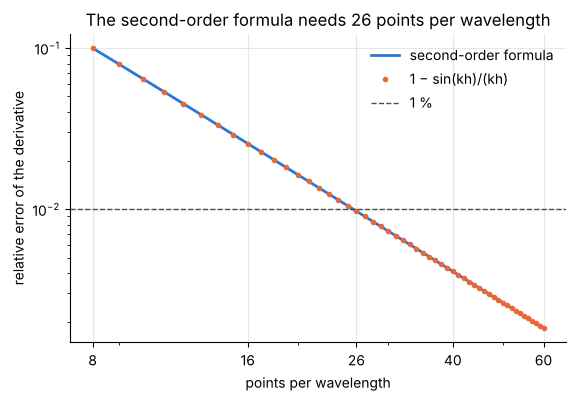

In [10]:
kh = brentq(lambda t: 1 - np.sin(t) / t - 0.01, 0.01, 1.0)      # without the small-kh approximation
print(f"1 % error at kh = {kh:.4f}, that is {2 * np.pi / kh:.1f} points per wavelength (estimate √0.06: {2 * np.pi / np.sqrt(0.06):.1f})")

def relative_error(D, N, k):
    """Largest error of D applied to sin(kx), relative to the amplitude k of the exact derivative."""
    x = 2 * np.pi * np.arange(N) / N
    return np.abs(D @ np.sin(k * x) - k * np.cos(k * x)).max() / k

points = np.arange(8, 61)
fd2_errors = np.array([relative_error(fd2_matrix(N), N, 1) for N in points])
for N in (24, 25, 26, 27):
    print(f"second order, {N} points per wavelength: error {100 * fd2_errors[points == N][0]:.2f} %")

N = 64
spectral_errors = {k: relative_error(fourier_diff_matrix(N), N, k) for k in (8, 24, 31, 32)}
for k, err in spectral_errors.items():
    print(f"spectral, N = {N}, k = {k:2d}: {N / k:5.2f} points per wavelength, relative error {err:.1e}")

fig, ax = plt.subplots()
ax.loglog(points, fd2_errors, label="second-order formula")
ax.loglog(points, 1 - np.sin(2 * np.pi / points) / (2 * np.pi / points), "o", ms=3, label="1 − sin(kh)/(kh)")
ax.axhline(0.01, color="0.3", lw=1, ls="--", label="1 %")
ax.set(xlabel="points per wavelength", ylabel="relative error of the derivative",
       title="The second-order formula needs 26 points per wavelength")
ax.set_xticks([8, 16, 26, 40, 60], labels=["8", "16", "26", "40", "60"])
ax.tick_params(axis="x", which="minor", labelbottom=False)
ax.legend(frameon=False, loc="upper right");

In [11]:
# verify: the measured errors against the formula of the exercise, and the 1 % threshold between 25 and 26 points
assert np.allclose(fd2_errors, 1 - np.sin(2 * np.pi / points) / (2 * np.pi / points), rtol=1e-9)
assert fd2_errors[points == 25][0] > 0.01 > fd2_errors[points == 26][0]
assert 25 < 2 * np.pi / kh < 26
assert max(spectral_errors[k] for k in (8, 24, 31)) < 1e-12 and abs(spectral_errors[32] - 1) < 1e-12

**Answer.** The second-order formula needs $2\pi/0.2453 = 25.6$, in practice 26, points per
wavelength for a 1 % error in the derivative: the measured error is 1.05 % with 25 points and
0.97 % with 26. The spectral matrix is exact to rounding for every wavenumber below $N/2$, so
it needs only a little more than **two** points per wavelength ($k = 31$ on 64 points is 2.06).
At exactly two, $k = N/2$, the samples of $\sin(kx)$ are all zero and the wave is lost
completely (relative error 1). For a wave-propagation problem with many wavelengths in the
domain, this factor of about ten per direction is the practical case for spectral methods.

## Exercise 5

Build the second-derivative matrix from the second-order formula
$(u_{j+1} - 2u_j + u_{j-1})/h^2$ and compare it with `fd2_matrix(N) @ fd2_matrix(N)`. Are
they the same matrix? Which is more accurate for the piston acceleration?

Multiply out the product by hand first. Applying $(u_{j+1} - u_{j-1})/2h$ twice gives

$$\frac{u_{j+2} - 2u_j + u_{j-2}}{4h^2} ,$$

which is the standard three-point formula on a grid of spacing $2h$. So the two matrices are
different, and since the error of the three-point formula is $\tfrac{1}{12}h^2 u''''$, the
squared matrix should be less accurate by a factor of $2^2 = 4$.

In [12]:
def fd2_second_matrix(N):
    """Second-order matrix for the second derivative, (u_{j+1} - 2u_j + u_{j-1})/h², on a periodic grid."""
    h = 2 * np.pi / N
    identity = np.eye(N)
    return (np.roll(identity, 1, axis=1) - 2 * identity + np.roll(identity, -1, axis=1)) / h**2

print("     N    compact formula    fd2 @ fd2    ratio")
compact_errors, squared_errors = [], []
for N in (32, 64, 128):
    x = 2 * np.pi * np.arange(N) / N
    compact_errors.append(np.abs(fd2_second_matrix(N) @ position(x) - acceleration(x)).max())
    squared_errors.append(np.abs(fd2_matrix(N) @ fd2_matrix(N) @ position(x) - acceleration(x)).max())
    print(f"{N:6d} {compact_errors[-1]:14.2e} {squared_errors[-1]:14.2e} {squared_errors[-1] / compact_errors[-1]:9.2f}")

N = 8
h = 2 * np.pi / N
print("\nrow 0 times h², compact:  ", np.round(fd2_second_matrix(N)[0] * h**2, 2))
print("row 0 times h², fd2 @ fd2:", np.round((fd2_matrix(N) @ fd2_matrix(N))[0] * h**2, 2))
sawtooth = (-1.0) ** np.arange(N)
print("applied to the sawtooth (-1)^j, times h²:", (fd2_second_matrix(N) @ sawtooth * h**2)[:2].round(12),
      "(compact) ", (fd2_matrix(N) @ fd2_matrix(N) @ sawtooth * h**2)[:2].round(12), "(fd2 @ fd2)")

     N    compact formula    fd2 @ fd2    ratio
    32       7.12e-03       2.83e-02      3.97
    64       1.78e-03       7.12e-03      3.99
   128       4.46e-04       1.78e-03      4.00

row 0 times h², compact:   [-2.  1.  0.  0.  0.  0.  0.  1.]
row 0 times h², fd2 @ fd2: [-0.5   0.    0.25  0.    0.    0.    0.25  0.  ]
applied to the sawtooth (-1)^j, times h²: [-4.  4.] (compact)  [0. 0.] (fd2 @ fd2)


In [13]:
# verify: the hand calculation (fd2 @ fd2 is the compact formula with spacing 2h), the factor 4 and the order 2
for N in (16, 64):
    wide = (np.roll(np.eye(N), 2, axis=1) - 2 * np.eye(N) + np.roll(np.eye(N), -2, axis=1)) / (2 * 2 * np.pi / N) ** 2
    assert np.allclose(fd2_matrix(N) @ fd2_matrix(N), wide)
    assert not np.allclose(fd2_matrix(N) @ fd2_matrix(N), fd2_second_matrix(N))
assert all(abs(s / c - 4) < 0.05 for s, c in zip(squared_errors, compact_errors))
assert abs(np.log2(compact_errors[0] / compact_errors[2]) / 2 - 2) < 0.02       # second order: the error falls 16 times from N = 32 to 128
assert np.abs(fd2_matrix(8) @ fd2_matrix(8) @ sawtooth).max() < 1e-12

**Answer.** They are not the same matrix. `fd2_matrix(N) @ fd2_matrix(N)` has the stencil
$(1, 0, -2, 0, 1)/4h^2$, the three-point formula with twice the spacing. Both are second-order
accurate, but the compact formula is 4 times more accurate for the piston acceleration: at
$N = 64$ its error is $1.8\times10^{-3}$ against $7.1\times10^{-3}$. The squared matrix has a
second defect: it links only every other grid point, so it returns zero for the sawtooth
$(-1)^j$, the most oscillatory data the grid can hold, where the compact formula returns the
large value $-4/h^2$. A discretization that cannot see a grid-scale oscillation cannot damp it
either, which matters as soon as such a matrix is used to solve an equation. Squaring a
first-derivative matrix is safe for the spectral matrix of 1.7 on smooth data, and a poor idea
for low-order finite differences.